In [105]:
# from ultralytics import SAM
from ultralytics.models.sam import Predictor as SAMPredictor, SAM2VideoPredictor

# Load a model
# model = SAM("sam_b.pt")
# dict_keys(['sam_h.pt', 'sam_l.pt', 'sam_b.pt', 'mobile_sam.pt', 'sam2_t.pt', 'sam2_s.pt', 'sam2_b.pt', 'sam2_l.pt', 'sam2.1_t.pt', 'sam2.1_s.pt', 'sam2.1_b.pt', 'sam2.1_l.pt'])

# model_name = "mobile_sam"
# model_name = "sam_b"
model_name = "sam_l"
# prefix = ""
# prefix = "sharpened_"
prefix = "sharpened_2_"
overrides = {"conf": 0.25, "task": "segment", "mode": "predict", "model": f"{model_name}.pt", "save": False, "device": "cuda"}
predictor = SAMPredictor(overrides=overrides)

# model_name = "sam2_l"
# overrides = {"conf": 0.25, "task": "segment", "mode": "predict", "imgsz": 1024, "model": f"{model_name}.pt"}
# predictor = SAM2VideoPredictor(overrides=overrides)

In [106]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from tqdm import tqdm

In [107]:
images = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\images'
masks = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\masks'
 
MODES = [
    "box", 
    "point", 
    # "vertex", 
    # "box+point", 
    # "box+vertex", 
    # "point+vertex"
    ]
N_OUT = 3    

In [108]:
# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def show_mask(mask,ax, random_color=False):

    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)


def iou(gt, pred):
    gt = gt > 0
    pred = pred > 0
    union = np.logical_or(gt, pred).sum()
    return 1.0 if union == 0 else np.logical_and(gt, pred).sum() / union
 
 
def interior_point(poly, H, W):
    """A point guaranteed to lie inside the polygon (works for concave shapes)."""
    m = np.zeros((H, W), dtype=np.uint8)
    cv2.fillPoly(m, [np.round(poly).astype(np.int32).reshape(-1, 1, 2)], 1)
    if m.sum() == 0:                       # degenerate polygon -> fall back to the mean
        return poly.mean(0).tolist()
    dist = cv2.distanceTransform(m, cv2.DIST_L2, 5)
    y, x = np.unravel_index(np.argmax(dist), dist.shape)
    return [float(x), float(y)]
 
 
def to_hw(m, H, W):
    """Make sure a mask is (H, W) bool."""
    if m.shape != (H, W):
        m = cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST)
    return m.astype(bool)

In [109]:
image_count = 300          # set to None to run on every image
save_chart = True

  0%|          | 0/300 [00:00<?, ?it/s]

Ultralytics 8.4.155  Python-3.12.0 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8123MiB)

0: 640x640 1 0, 1 1, 1 2, 4.5ms
Speed: 2.0ms preprocess, 4.5ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 3.4ms
Speed: 2.0ms preprocess, 3.4ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 4.1ms
Speed: 3.8ms preprocess, 4.1ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 3.7ms
Speed: 2.9ms preprocess, 3.7ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 3.3ms
Speed: 2.0ms preprocess, 3.3ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 5.0ms
Speed: 2.5ms preprocess, 5.0ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 4.1ms
Speed: 1.9ms preprocess, 4.1ms inference, 0.7ms postprocess per image at shape (1, 3, 

  0%|          | 1/300 [00:02<11:27,  2.30s/it]

1 IoU: {'box 1': np.float64(0.924), 'box 2': np.float64(0.879), 'box 3': np.float64(0.915), 'point 1': np.float64(0.836), 'point 2': np.float64(0.848), 'point 3': np.float64(0.712)}
  box  : (0.924 + 0.879 + 0.915) / 3 = 0.906   best = 0.924
  point: (0.836 + 0.848 + 0.712) / 3 = 0.799   best = 0.848

0: 640x640 1 0, 1 1, 1 2, 4.2ms
Speed: 2.1ms preprocess, 4.2ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 4.9ms
Speed: 5.2ms preprocess, 4.9ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)


  1%|          | 2/300 [00:02<05:25,  1.09s/it]

...

52 IoU: {'box 1': np.float64(0.907), 'box 2': np.float64(0.584), 'box 3': np.float64(0.749), 'point 1': np.float64(0.705), 'point 2': np.float64(0.473), 'point 3': np.float64(0.839)}
  box  : (0.907 + 0.584 + 0.749) / 3 = 0.747   best = 0.907
  point: (0.705 + 0.473 + 0.839) / 3 = 0.672   best = 0.839

0: 640x640 1 0, 1 1, 1 2, 3.9ms
Speed: 2.3ms preprocess, 3.9ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 3.9ms
Speed: 4.2ms preprocess, 3.9ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 3.7ms
Speed: 3.2ms preprocess, 3.7ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 3.8ms
Speed: 3.0ms preprocess, 3.8ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 4.0ms
Speed: 2.2ms preprocess, 4.0ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 3.3ms
Speed: 2.4ms prepro

100%|█████████▉| 299/300 [02:10<00:00,  2.76it/s]

53 IoU: {'box 1': np.float64(0.831), 'box 2': np.float64(0.892), 'box 3': np.float64(0.874), 'point 1': np.float64(0.778), 'point 2': np.float64(0.715), 'point 3': np.float64(0.751)}
  box  : (0.831 + 0.892 + 0.874) / 3 = 0.866   best = 0.892
  point: (0.778 + 0.715 + 0.751) / 3 = 0.748   best = 0.778

0: 640x640 1 0, 1 1, 1 2, 3.4ms
Speed: 2.1ms preprocess, 3.4ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 4.0ms
Speed: 2.2ms preprocess, 4.0ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 5.9ms
Speed: 2.3ms preprocess, 5.9ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 7.0ms
Speed: 2.2ms preprocess, 7.0ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 3.3ms
Speed: 2.2ms preprocess, 3.3ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 0, 1 1, 1 2, 3.4ms
Speed: 2.0ms prepro

100%|██████████| 300/300 [02:11<00:00,  2.29it/s]

54 IoU: {'box 1': np.float64(0.898), 'box 2': np.float64(0.848), 'box 3': np.float64(0.914), 'point 1': np.float64(0.839), 'point 2': np.float64(0.424), 'point 3': np.float64(0.823)}
  box  : (0.898 + 0.848 + 0.914) / 3 = 0.887   best = 0.914
  point: (0.839 + 0.424 + 0.823) / 3 = 0.695   best = 0.839
Mean IoU per output slot:
  box 1: 0.886
  box 2: 0.838
  box 3: 0.871
  point 1: 0.741
  point 2: 0.439
  point 3: 0.553

Per-mode average IoU over 300 image(s):
  box  : (0.924 + 0.946 + 0.929 + 0.925 + 0.833 + 0.862 + 0.878 + 0.862 + 0.800 + 0.866 + 0.956 + 0.852 + 0.962 + 0.931 + 0.924 + 0.859 + 0.918 + 0.931 + 0.931 + 0.837 + 0.971 + 0.937 + 0.896 + 0.895 + 0.876 + 0.897 + 0.874 + 0.942 + 0.908 + 0.913 + 0.797 + 0.846 + 0.832 + 0.875 + 0.945 + 0.864 + 0.894 + 0.894 + 0.910 + 0.895 + 0.905 + 0.887 + 0.832 + 0.867 + 0.954 + 0.946 + 0.888 + 0.933 + 0.844 + 0.826 + 0.873 + 0.896 + 0.896 + 0.829 + 0.920 + 0.914 + 0.933 + 0.882 + 0.917 + 0.891 + 0.903 + 0.831 + 0.795 + 0.869 + 0.912 + 0.92

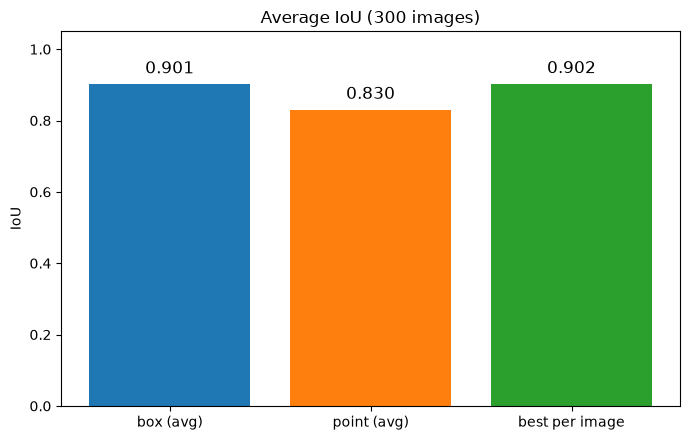

In [110]:
# ---------------------------------------------------------------------------
# Main loop
# ---------------------------------------------------------------------------
best_ious = []           # best of the 6 outputs, per image
all_ious = []            # all 6 values, per image
mode_mean = {mode: [] for mode in MODES}   # mean of the 3 outputs, per image
mode_best = {mode: [] for mode in MODES}   # best of the 3 outputs, per image
 
img_paths = sorted(glob(os.path.join(images, '*.png')))
if image_count:
    img_paths = img_paths[:image_count]
 
for img_path in tqdm(img_paths):
    stem = os.path.splitext(os.path.basename(img_path))[0]
 
    # Match the mask and JSON by file name instead of zipping two globs
    mask_path = os.path.join(masks, stem + '.png')
    json_path = os.path.join(images, stem + '.json')
    if not (os.path.exists(mask_path) and os.path.exists(json_path)):
        print(f"{stem}: missing mask or json, skipped")
        continue
 
    image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    H, W = image.shape[:2]
    gt = to_hw(cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) > 0, H, W)
 
    with open(json_path) as fh:
        ann = json.load(fh)
    polygons = [np.array(s['points'], dtype=np.float32).reshape(-1, 2)
                for s in ann['shapes'] if len(s['points']) >= 3]
 

    # # Create a Gaussian blurred version of the image
    # gaussian_blur = cv2.GaussianBlur(image, (9, 9), 10.0)

    # # Blend the original and blurred image to enhance the fine details
    # # formula: sharpened = original * alpha + blurred * beta + gamma
    # image = cv2.addWeighted(image, 1.5, gaussian_blur, -0.5, 0)

    #---------------------------------------------------------------

    if prefix == "sharpened_":
        # CLAHE works best on the Luminance channel of a LAB image
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
        l_channel, a, b = cv2.split(lab)

        # Apply CLAHE
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l_channel)

        # Merge back and convert to BGR
        merged = cv2.merge((cl, a, b))
        image = cv2.cvtColor(merged, cv2.COLOR_LAB2BGR)

    #---------------------------------------------------------------

    if prefix == "sharpened_2_":
        # Local contrast boost on luminance only (keeps colors natural)
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l = clahe.apply(l)
        img = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

        # Edge-preserving denoise (smooths texture noise, keeps boundaries)
        img = cv2.bilateralFilter(img, d=7, sigmaColor=50, sigmaSpace=50)

        # Mild unsharp mask to crisp up edges
        blur = cv2.GaussianBlur(img, (0, 0), 3)
        img = cv2.addWeighted(img, 1.5, blur, -0.5, 0)

        # SAM expects RGB
        image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    #---------------------------------------------------------------

    # # Initialize Super Resolution model (e.g., FSRCNN, EDSR, ESPCN)
    # sr = cv2.dnn_superres.DnnSuperResImpl_create()

    # # Download a pre-trained model file (like FSRCNN_x3.pb) and load it
    # path = "FSRCNN_x3.pb"
    # sr.readModel(path)
    # sr.setModel("fsrcnn", 3) # scale factor 3x

    # image = sr.upsample(image)

    #---------------------------------------------------------------

    predictor.set_image(image)
 
    # One set of 3 tiles per mode -> 6 predictions in total
    pred_tiles = {mode: np.zeros((N_OUT, H, W), dtype=bool) for mode in MODES}
 
    for mode in MODES:
        for poly in polygons:
            if mode == "box":
                kwargs = {"bboxes": [[*poly.min(0), *poly.max(0)]]}
            else:
                kwargs = {"points": [interior_point(poly, H, W)], "labels": [1]}
 
            results = predictor(multimask_output=True, save=False, **kwargs)
            for res in results:
                if res.masks is None:
                    continue
                pred = res.masks.data.cpu().numpy()          # (K, H, W)
                for k in range(min(N_OUT, pred.shape[0])):
                    pred_tiles[mode][k] |= to_hw(pred[k], H, W)
 
    # Flatten to 6 (label, mask, IoU) entries
    outputs = []
    for mode in MODES:
        for k in range(N_OUT):
            tile = pred_tiles[mode][k]
            outputs.append((f"{mode} {k + 1}", tile, iou(gt, tile)))
 
    ious = [v for _, _, v in outputs]
    best_idx = int(np.argmax(ious))
    best_ious.append(ious[best_idx])
    all_ious.append(ious)
    print(stem, "IoU:", {lbl: round(v, 3) for lbl, _, v in outputs})
 
    # ---- Per-mode average for this image ----
    mode_text = []
    for m_i, mode in enumerate(MODES):
        mode_vals = ious[m_i * N_OUT:(m_i + 1) * N_OUT]
        mean_v, best_v = np.mean(mode_vals), np.max(mode_vals)
        mode_mean[mode].append(mean_v)
        mode_best[mode].append(best_v)
        calc = " + ".join(f"{v:.3f}" for v in mode_vals)
        print(f"  {mode:5s}: ({calc}) / {len(mode_vals)} = {mean_v:.3f}   best = {best_v:.3f}")
        mode_text.append(f"{mode} avg = {mean_v:.3f} (best {best_v:.3f})")
 
    # # ---- Plot: ground truth + 6 outputs ----
    # fig, axes = plt.subplots(1, 1 + len(outputs), figsize=(5 * (1 + len(outputs)), 5))
 
    # axes[0].imshow(image)
    # show_mask(gt, axes[0])
    # axes[0].set_title("Ground truth", fontsize=14)
    # axes[0].axis('off')
 
    # for i, (label, tile, v) in enumerate(outputs):
    #     ax = axes[i + 1]
    #     ax.imshow(image)
    #     show_mask(tile, ax)
    #     best = i == best_idx
    #     ax.set_title(f"{label}, IoU: {v:.3f}" + (" (best)" if best else ""),
    #                  fontsize=14, color='red' if best else 'black')
    #     ax.axis('off')
 
    # fig.suptitle(f"{stem}   |   " + "   |   ".join(mode_text), fontsize=16)
    # plt.tight_layout()
    # plt.show()
 
# ---- Summary ----
if best_ious:
    n = len(best_ious)
 
    mean_per_slot = np.mean(all_ious, axis=0)
    labels = [f"{m} {k + 1}" for m in MODES for k in range(N_OUT)]
    print("Mean IoU per output slot:")
    for lbl, v in zip(labels, mean_per_slot):
        print(f"  {lbl}: {v:.3f}")
 
    # ---- Average of each mode (best of its 3 outputs, per image) ----
    print(f"\nPer-mode average IoU over {n} image(s):")
    mode_avg = {}
    for mode in MODES:
        bests = mode_best[mode]
        mode_avg[mode] = np.mean(bests)
        calc = " + ".join(f"{v:.3f}" for v in bests)
        print(f"  {mode:5s}: ({calc}) / {n} = {mode_avg[mode]:.3f}")
 
    # ---- Average of the overall best per image (best of all 6 outputs) ----
    overall_avg = np.mean(best_ious)
    calc = " + ".join(f"{v:.3f}" for v in best_ious)
    print(f"  best per image (any mode): ({calc}) / {n} = {overall_avg:.3f}")
 
    # ---- Bar chart ----
    bar_labels = [f"{m} (avg)" for m in MODES] + ["best per image"]
    bar_values = [mode_avg[m] for m in MODES] + [overall_avg]
    colors = ["tab:blue", "tab:orange", "tab:green"][:len(bar_labels)]
 
    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(bar_labels, bar_values, color=colors)
    for b, v in zip(bars, bar_values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}",
                ha="center", va="bottom", fontsize=12)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("IoU")
    ax.set_title(f"Average IoU ({n} images)")
    plt.tight_layout()
    if save_chart:
        os.makedirs("./test_results", exist_ok=True)
        plt.savefig(f"./test_results/{prefix}{model_name}-{image_count}.png")
    plt.show()
 
 